In [1]:
%load_ext autoreload
%autoreload 2

import json
import pandas as pd
import matplotlib.pyplot as plt
from demandfcst import config, storage
from demandfcst.eda import load as L, style

style.apply()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

info = json.loads(storage.read_text(storage.join(config.pipeline_paths()["processed"], "run_info.json")))
print("data version:", "data-" + info["latest_drops"]["sellin_daily"])

wk = L.weekly_enriched()
FIRST_WEEK, LAST_WEEK = wk["week_start"].min(), wk["week_start"].max()
ALL_WEEKS = wk["week_start"].nunique()
print(f"{wk.shape} | weeks {FIRST_WEEK.date()} → {LAST_WEEK.date()} ({ALL_WEEKS})")


data version: data-2025-03-23
(47236, 19) | weeks 2021-01-04 → 2025-03-17 (220)


In [2]:
prof = (wk.groupby(["series", "province", "region", "sku_id", "sku_name", "container"], as_index=False)
          .agg(first=("week_start", "min"), last=("week_start", "max"),
               weeks=("week_start", "size"),
               zero_weeks=("volume_hl", lambda s: int((s == 0).sum())),
               total_hl=("volume_hl", "sum")))
prof["zero_share"] = (prof["zero_weeks"] / prof["weeks"]).round(3)
prof["starts_late"] = prof["first"] > FIRST_WEEK
prof["ends_early"] = prof["last"] < LAST_WEEK

full = (~prof["starts_late"] & ~prof["ends_early"]).sum()
print(f"{len(prof)} series | full history: {full} | start late: {prof['starts_late'].sum()} "
      f"| end early: {prof['ends_early'].sum()}")
prof["weeks"].describe().round(1)


231 series | full history: 190 | start late: 30 | end early: 11


count    231.0
mean     204.5
std       42.1
min       51.0
25%      220.0
50%      220.0
75%      220.0
max      220.0
Name: weeks, dtype: float64

In [3]:
cols = ["series", "sku_name", "first", "last", "weeks", "zero_share", "total_hl"]
print("STARTS LATE")
print(prof[prof["starts_late"]].sort_values("first")[cols].to_string(index=False))
print("\nENDS EARLY")
print(prof[prof["ends_early"]].sort_values("last")[cols].to_string(index=False))


STARTS LATE
  series                   sku_name      first       last  weeks  zero_share  total_hl
BA·49327          CORONA LATA 473ML 2021-01-11 2025-03-17    219       0.425 11072.225
BA·81704     SPATEN LONG NECK 330ML 2021-01-11 2025-03-17    219       0.671 10703.595
RS·44863        ORIGINAL BARRIL 30L 2021-01-11 2025-03-17    219       0.269  9117.030
PE·81704     SPATEN LONG NECK 330ML 2021-01-11 2025-03-17    219       0.639  5716.211
PE·84931 ANTARCTICA LONG NECK 330ML 2021-01-11 2025-03-17    219       0.616 12590.509
PR·22581   STELLA ARTOIS BARRIL 30L 2021-01-11 2025-03-17    219       0.411  6569.489
SC·80260   STELLA ARTOIS LATA 269ML 2021-01-18 2025-03-17    218       0.509 10798.719
BA·10662          SPATEN LATA 473ML 2021-01-25 2025-03-17    217       0.544  7692.742
SP·13353      ANTARCTICA BARRIL 30L 2021-02-01 2025-03-17    216       0.491 44916.801
RS·51300   ORIGINAL LONG NECK 330ML 2022-03-07 2025-03-17    159       0.396  4023.252
SP·51300   ORIGINAL LONG NECK 3

In [4]:
print("STARTS LATE, by first week:")
print(prof[prof["starts_late"]].groupby("first").agg(series=("series", "size"),
                                                    skus=("sku_name", lambda s: ", ".join(sorted(set(s))))))
print("\nENDS EARLY, by last week:")
print(prof[prof["ends_early"]].groupby("last").agg(series=("series", "size"),
                                                  skus=("sku_name", lambda s: ", ".join(sorted(set(s))))))


STARTS LATE, by first week:
            series                                               skus
first                                                                
2021-01-11       6  ANTARCTICA LONG NECK 330ML, CORONA LATA 473ML,...
2021-01-18       1                           STELLA ARTOIS LATA 269ML
2021-01-25       1                                  SPATEN LATA 473ML
2021-02-01       1                              ANTARCTICA BARRIL 30L
2022-03-07       2                           ORIGINAL LONG NECK 330ML
2022-03-21       1                           ORIGINAL LONG NECK 330ML
2022-10-03       3                                  SPATEN LATA 269ML
2022-10-17       1                                  SPATEN LATA 269ML
2023-06-05       4                               BUDWEISER LATA 269ML
2023-06-12       1                               BUDWEISER LATA 269ML
2024-04-01       9                               BUDWEISER LATA 350ML

ENDS EARLY, by last week:
            series                 

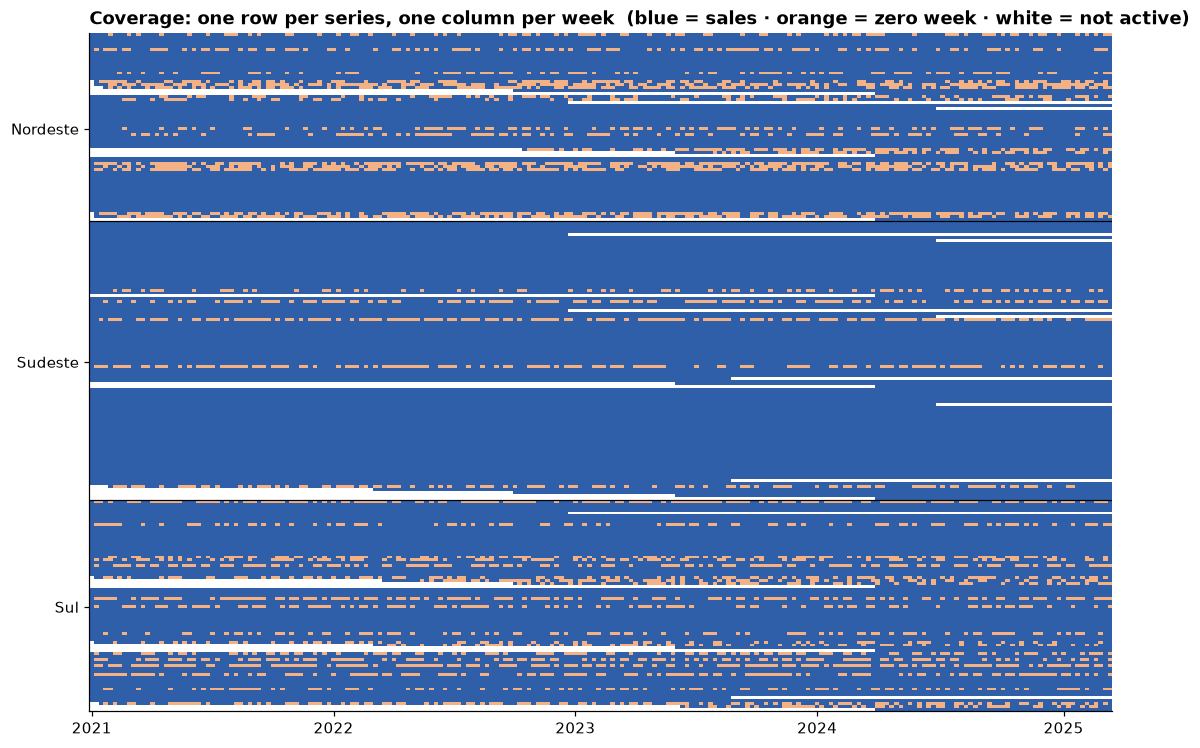

In [5]:
import numpy as np
from matplotlib.colors import ListedColormap

state = wk.assign(state=np.where(wk["volume_hl"] > 0, 2, 1))
grid = state.pivot_table(index="series", columns="week_start", values="state", aggfunc="max", fill_value=0)

order = prof.sort_values(["region", "province", "first", "sku_id"])["series"]
grid = grid.reindex(order)
regions = prof.set_index("series").loc[order, "region"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(grid.values, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#ffffff", "#f4b183", "#2f5fa8"]), vmin=0, vmax=2)
ax.grid(False)

year_starts = [i for i, d in enumerate(grid.columns) if d.month == 1 and d.day <= 7]
ax.set_xticks(year_starts, [grid.columns[i].year for i in year_starts])
bounds = [0] + [i for i in range(1, len(regions)) if regions[i] != regions[i - 1]] + [len(regions)]
for b in bounds[1:-1]:
    ax.axhline(b - 0.5, color="black", lw=0.8)
ax.set_yticks([(a + b) / 2 for a, b in zip(bounds, bounds[1:])], [regions[a] for a in bounds[:-1]])
ax.set_title("Coverage: one row per series, one column per week  (blue = sales · orange = zero week · white = not active)")
style.save(fig, "fig_4_1_coverage_heatmap")
plt.show()


In [6]:
by_region = (prof.assign(sparse=prof["zero_share"] > 0.2)
                 .groupby("region")
                 .agg(series=("series", "size"),
                      sparse_series=("sparse", "sum"),
                      zero_weeks=("zero_weeks", "sum"),
                      weeks=("weeks", "sum"),
                      volume_hl=("total_hl", "sum")))
by_region["sparse_share"] = (by_region["sparse_series"] / by_region["series"]).round(2)
by_region["zero_week_share"] = (by_region["zero_weeks"] / by_region["weeks"]).round(3)
by_region["volume_share"] = (by_region["volume_hl"] / by_region["volume_hl"].sum()).round(3)
by_region[["series", "sparse_series", "sparse_share", "zero_week_share", "volume_share"]]


,series,sparse_series,sparse_share,zero_week_share,volume_share
region,,,,,
Nordeste,64,17,0.27,0.132,0.172
Sudeste,95,5,0.05,0.029,0.607
Sul,72,20,0.28,0.131,0.221


In [7]:
def summarise(prof, by, sparse_threshold=0.2):
    """Series, sparsity and volume share per group (region, province, SKU, ...)."""
    out = (prof.assign(sparse=prof["zero_share"] > sparse_threshold)
               .groupby(by)
               .agg(series=("series", "size"),
                    sparse_series=("sparse", "sum"),
                    zero_weeks=("zero_weeks", "sum"),
                    weeks=("weeks", "sum"),
                    volume_hl=("total_hl", "sum")))
    out["sparse_share"] = (out["sparse_series"] / out["series"]).round(2)
    out["zero_week_share"] = (out["zero_weeks"] / out["weeks"]).round(3)
    out["volume_share"] = (out["volume_hl"] / out["volume_hl"].sum()).round(3)
    cols = ["series", "sparse_series", "sparse_share", "zero_week_share", "volume_share"]
    return out[cols].sort_values("volume_share", ascending=False)

by_province = summarise(prof, ["region", "province"])
by_province


series  sparse_series  sparse_share  zero_week_share  volume_share
region   province                                                                    
Sudeste  SP            38              1          0.03            0.014         0.363
         RJ            31              3          0.10            0.063         0.136
         MG            26              1          0.04            0.013         0.108
Sul      RS            22              5          0.23            0.095         0.093
         PR            30              8          0.27            0.125         0.086
Nordeste BA            21              6          0.29            0.144         0.064
         PE            22              5          0.23            0.147         0.058
         CE            21              6          0.29            0.103         0.051
Sul      SC            20              7          0.35            0.180         0.041

In [8]:
cols = ["series", "sku_name", "container", "zero_share", "total_hl"]
print("Sparse series (> 20% zero weeks):")
print(prof[prof["province"].isin(["RJ", "MG"]) & (prof["zero_share"] > 0.2)]
      .sort_values(["province", "zero_share"], ascending=[True, False])[cols].to_string(index=False))

rj = set(prof.loc[prof["province"] == "RJ", "sku_name"])
mg = set(prof.loc[prof["province"] == "MG", "sku_name"])
only_rj = prof[(prof["province"] == "RJ") & prof["sku_name"].isin(rj - mg)]
print(f"\nProducts sold in RJ but not in MG: {len(only_rj)}")
print(only_rj.sort_values("total_hl")[cols].to_string(index=False))


Sparse series (> 20% zero weeks):
  series              sku_name container  zero_share  total_hl
MG·84911     SPATEN BARRIL 30L       keg       0.318  6788.433
RJ·34938     BRAHMA BARRIL 30L       keg       0.677 24740.776
RJ·82428  BUDWEISER BARRIL 30L       keg       0.586 21954.687
RJ·13353 ANTARCTICA BARRIL 30L       keg       0.536 12275.237

Products sold in RJ but not in MG: 10
  series                  sku_name container  zero_share  total_hl
RJ·52436         CORONA BARRIL 30L       keg       0.000 10713.527
RJ·13353     ANTARCTICA BARRIL 30L       keg       0.536 12275.237
RJ·90806  STELLA ARTOIS LATA 350ML       can       0.000 14208.246
RJ·73000      BUDWEISER LATA 269ML       can       0.000 21864.715
RJ·80812     ANTARCTICA LATA 473ML       can       0.000 33955.557
RJ·85730       ORIGINAL LATA 350ML       can       0.000 39485.040
RJ·71410 BUDWEISER LONG NECK 330ML    bottle       0.000 41381.432
RJ·38103   BUDWEISER GARRAFA 600ML    bottle       0.000 50567.646
RJ·69829 

In [9]:
print("By container:")
print(summarise(prof, "container"))

print("\nKegs vs non-kegs, by province:")
keg_view = summarise(prof.assign(is_keg=prof["container"].eq("keg").map({True: "keg", False: "can/bottle"})),
                     ["province", "is_keg"])
print(keg_view.reset_index().pivot(index="province", columns="is_keg", values="zero_week_share")
              .reindex(by_province.index.get_level_values("province")))


By container:
           series  sparse_series  sparse_share  zero_week_share  volume_share
container                                                                    
can           126             12          0.10            0.045         0.646
bottle         61              8          0.13            0.066         0.273
keg            44             22          0.50            0.233         0.081

Kegs vs non-kegs, by province:
is_keg    can/bottle    keg
province                   
SP             0.000  0.060
RJ             0.000  0.300
MG             0.000  0.053
RS             0.045  0.304
PR             0.082  0.255
BA             0.133  0.189
PE             0.099  0.435
CE             0.059  0.332
SC             0.111  0.535


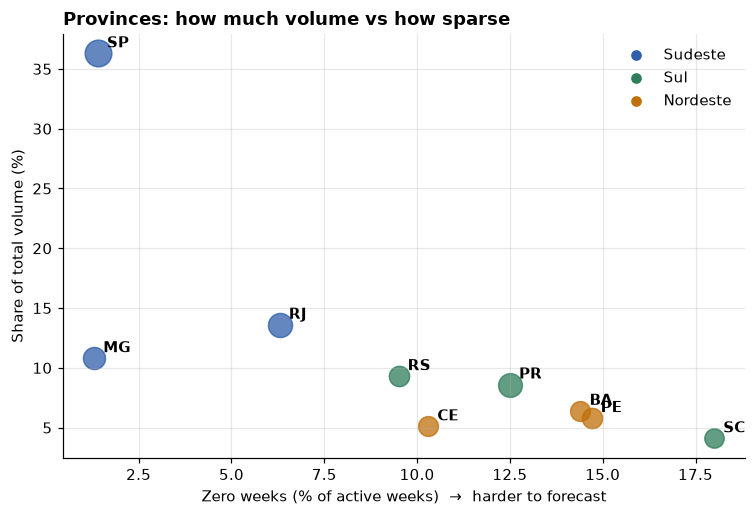

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
for (region, province), r in by_province.iterrows():
    ax.scatter(r["zero_week_share"] * 100, r["volume_share"] * 100,
               s=r["series"] * 8, color=style.REGION_COLORS[region], alpha=0.75)
    ax.annotate(province, (r["zero_week_share"] * 100, r["volume_share"] * 100),
                xytext=(6, 4), textcoords="offset points", fontweight="bold")
for region, color in style.REGION_COLORS.items():
    ax.scatter([], [], color=color, label=region)
ax.set_xlabel("Zero weeks (% of active weeks)  →  harder to forecast")
ax.set_ylabel("Share of total volume (%)")
ax.set_title("Provinces: how much volume vs how sparse")
ax.legend()
style.save(fig, "fig_4_1_province_volume_vs_sparsity")
plt.show()
